<a href="https://colab.research.google.com/github/AlaKh09/Mentalist/blob/Projet-ML/TheMentalistML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ensemble Learning pour la prédiction de maladies
**Cours :** AML, ESPRIT | **Article de référence :** Mahajan et al. (2024), *Health and Technology*, 14:597-613
**Données :** les 16 jeux de données médicaux de l'article de référence (Kaggle et UCI)

## Méthodologie : CRISP-DM + MLOps
Nous suivons les 6 phases de CRISP-DM, précédées d'une phase 0 (état de l'art).
Les pratiques MLOps sont appliquées dans chaque phase.

| Phase | Pratique MLOps utilisée |
|---|---|
| 0. État de l'art | Références et sources documentées |
| 1. Compréhension du métier | Objectifs (BO/DSO) et critères de succès définis avant les expériences |
| 2. Compréhension des données | Journal des sources et versionnement des données (nom, lien, taille, hash) |
| 3. Préparation des données | Pipeline de prétraitement réutilisable, graine aléatoire fixe (`random_state=42`) |
| 4. Modélisation | Suivi des expériences (MLflow) et versionnement des modèles |
| 5. Évaluation | Mêmes métriques et même validation croisée pour tous les modèles |
| 6. Déploiement | Meilleur modèle sauvegardé (joblib), README, exécution reproductible |

**Outils :** Python, scikit-learn, XGBoost, LightGBM, CatBoost, MLflow.

## 0. État de l'art

*Objectif : situer le travail par rapport à l'existant, justifier nos choix (modèles, métriques) et avoir un repère de performance.*

**Données.** Les 16 datasets viennent de Kaggle et d'UCI et couvrent 5 maladies chroniques : cœur (4), foie (3), diabète (4), rein (3) et peau (2). Ils ont été rassemblés par Mahajan et al. (2024).

**Pratiques courantes.**
* Un seul modèle peut faire du surapprentissage et être instable, donc la littérature utilise des méthodes ensemblistes : bagging (Random Forest), boosting (AdaBoost, XGBoost) et stacking.
* Protocole habituel : normalisation, GridSearchCV et validation croisée à 5 plis.

**Article de référence (Mahajan et al., 2024).** 15 méthodes testées sur 16 datasets avec 6 métriques. Le stacking est le meilleur dans l'ensemble (multi-niveaux : 50 meilleurs scores, classique : 48) et Logit Boost est le plus faible (20).

**Limites de l'article.**
* Datasets presque tous équilibrés, alors que les données cliniques sont souvent déséquilibrées.
* Risque de surapprentissage pour le stacking.
* Pas de test statistique ni d'écart-type, et certains scores très élevés (D4 : 99 %, D10 : 97 %) à contrôler.

**Pièges fréquents.** Fuite de données, accuracy seule sur des classes déséquilibrées, datasets très petits (D14 : 90 lignes), datasets multiclasses (D15, D16).

**Notre positionnement.** Protocole unique pour les 16 datasets, analyse centrée sur le **recall** (BO1) et **test statistique** pour vérifier si le stacking est vraiment meilleur (BO2).

**Références**
* Mahajan P., Uddin S., Hajati F., Moni M. A., Gide E. (2024). *A comparative evaluation of machine learning ensemble approaches for disease prediction using multiple datasets.* Health and Technology, 14, 597-613. doi:10.1007/s12553-024-00835-w
* À ajouter après lecture : 2 ou 3 travaux liés (par exemple Uddin et al., 2019, *BMC Medical Informatics and Decision Making*).

## 1. De l'objectif métier (BO) à l'objectif Data Science (DSO)

| | Objectif métier (BO) | Objectif Data Science (DSO) |
|---|---|---|
| **BO1** | Réduire les diagnostics manqués (patients malades non détectés) | Maximiser le **recall** des modèles sur les 16 datasets, en gardant une bonne precision, un bon F1 et un bon AUPRC |
| **BO2** | Aider les équipes médicales et data à choisir un modèle de prédiction fiable et stable pour plusieurs maladies chroniques | Comparer bagging, boosting et stacking avec 6 métriques (accuracy, precision, recall, F1, AUC, AUPRC) et vérifier si le stacking est la meilleure méthode, comme l'indiquent Mahajan et al. (2024) |

### 1.1 Compréhension métier — BO1 : Réduire les diagnostics manqués

| Élément | Description |
|---|---|
| **Contexte** | Les maladies chroniques (cœur, diabète, rein, foie, peau) touchent des millions de personnes. Un diagnostic tardif peut conduire à la mort. |
| **Problème métier** | Le diagnostic est difficile : les médecins décident vite et les symptômes sont complexes et différents pour chaque patient. Un patient malade classé « sain » ne reçoit pas de soins à temps. |
| **Parties prenantes** | Médecins (décision de diagnostic), équipes de santé et de dépistage, patients, équipes data qui construisent les modèles. |
| **Objectif métier** | Détecter le plus grand nombre possible de patients réellement malades, pour qu'ils soient pris en charge plus tôt. |
| **Critères de succès métier** | Pour chaque dataset, le meilleur modèle obtient le meilleur recall parmi les modèles comparés, sans que la precision ne s'effondre. |
| **Tâche Data Science** | Classification supervisée (binaire pour 14 datasets, multiclasse pour D15 et D16), avec le recall comme métrique prioritaire. |
| **Contraintes et risques** | Un malade manqué (faux négatif) coûte plus cher qu'une fausse alerte (faux positif) ; certains datasets sont petits (D14 : 90 lignes) ou déséquilibrés (D4, D6, D9, D10) ; les prédictions sont une aide au tri, pas une décision clinique. |

### 1.2 Compréhension métier — BO2 : Choisir un modèle fiable et stable

| Élément | Description |
|---|---|
| **Contexte** | Un seul modèle peut faire du surapprentissage et être instable quand les données changent. L'apprentissage ensembliste (bagging, boosting, stacking) combine plusieurs modèles pour mieux prédire. |
| **Problème métier** | On ne sait pas clairement quelle méthode ensembliste est la meilleure pour la prédiction de maladies. Mahajan et al. (2024) trouvent que le stacking est le meilleur, mais sans écart-type ni test statistique, et avec des datasets presque tous équilibrés. |
| **Parties prenantes** | Équipes data et chercheurs (choix du modèle), équipes médicales qui utilisent ces outils d'aide, enseignante qui évalue le projet. |
| **Objectif métier** | Disposer d'une recommandation claire, fondée sur des résultats prouvés, pour choisir la méthode ensembliste adaptée à plusieurs maladies. |
| **Critères de succès métier** | Tous les modèles sont comparés avec les mêmes découpages, la même validation croisée et les 6 métriques ; la méthode recommandée reste stable d'un dataset à l'autre. |
| **Tâche Data Science** | Comparaison de 3 familles ensemblistes sur 16 datasets, tableaux modèle × dataset, nombre de fois « meilleur » et test statistique (ex. Friedman). |
| **Contraintes et risques** | Données publiques et non cliniques (pas de validation à l'hôpital) ; résultats de l'article difficiles à reproduire exactement (protocole différent) ; risque de fuite de données si le prétraitement se fait avant le découpage ; coût de calcul élevé pour le stacking. |

**Lien entre les deux objectifs :** le BO1 définit ce qu'on veut maximiser (le recall), et le BO2 définit comment on choisit le modèle (comparaison rigoureuse). Ensemble, ils donnent une méthode recommandée qui détecte bien les malades et qui reste fiable d'un dataset à l'autre.

### 1.3 Critères de succès globaux (défini avant les expériences)
* BO1 : classement des modèles par recall, puis par F1 et AUPRC.
* BO2 : verdict argumenté sur le stacking, avec test statistique.
* Livrable : une recommandation de la meilleure méthode, avec les limites du travail.

# 2. Compréhension des données (Data Understanding)

## 2.1 Présentation des datasets

Le projet utilise les **16 jeux de données** de l'article de référence (Mahajan et al., 2024), publiés sur Kaggle et sur le dépôt UCI Machine Learning Repository.

Ils portent sur **5 maladies chroniques** :

- Maladies cardiaques : 4 datasets (D1 à D4)
- Maladies du foie : 3 datasets (D5 à D7)
- Diabète : 4 datasets (D8 à D11)
- Maladies rénales : 3 datasets (D12 à D14)
- Maladies de la peau : 2 datasets (D15 à D16)

Au total, ils contiennent **18 857 observations** (patients ou lésions). Ils ont des tailles très différentes, de 90 à 10 015 lignes, et de 6 à 35 attributs.

| ID | Dataset | Maladie | Source | Attributs | Lignes | Positifs / Négatifs |
|---|---|---|---|---|---|---|
| D1 | Heart Disease (Comprehensive) | Cœur | Kaggle | 11 | 1190 | 629 / 561 |
| D2 | Heart attack possibility | Cœur | Kaggle | 13 | 303 | 165 / 138 |
| D3 | Heart Disease Dataset | Cœur | Kaggle | 13 | 1025 | 526 / 499 |
| D4 | Heart Failure Prediction | Cœur | Kaggle | 12 | 299 | 96 / 203 |
| D5 | Liver Disorders | Foie | UCI | 7 | 345 | 200 / 145 |
| D6 | Indian Liver Patient | Foie | UCI | 10 | 583 | 167 / 416 |
| D7 | COVID-19 effect on liver cancer | Foie | Kaggle | 25 | 450 | 310 / 140 |
| D8 | Early-stage diabetes risk | Diabète | UCI | 16 | 520 | 320 / 200 |
| D9 | Diabetes (KNN) | Diabète | Kaggle | 7 | 768 | 268 / 500 |
| D10 | Diabetes Dataset 2019 | Diabète | Kaggle | 17 | 952 | 267 / 685 |
| D11 | Diabetic Retinopathy Debrecen | Diabète | UCI | 18 | 1151 | 611 / 540 |
| D12 | Chronic Kidney Dataset | Rein | Kaggle | 25 | 400 | 150 / 250 |
| D13 | Chronic Kidney Disease | Rein | Kaggle | 13 | 400 | 250 / 150 |
| D14 | Kidney Stone | Rein | Kaggle | 7 | 90 | 45 / 45 |
| D15 | Skin Cancer MNIST : HAM10000 | Peau | Kaggle | 6 | 10015 | Multiclasse |
| D16 | Dermatology | Peau | UCI | 35 | 366 | Multiclasse |

*Source : Table 2 de Mahajan et al. (2024). Pour D4, la colonne « Positifs » correspond aux décès (96) et « Négatifs » aux survivants (203).*

**Caractéristiques générales**

- **Tâche :** classification supervisée. 14 datasets sont binaires (malade / non malade). D15 et D16 sont **multiclasses**, donc les métriques demandent un choix de moyenne (macro ou weighted).
- **Types de variables :** numériques (âge, tension, cholestérol, glycémie, etc.) et catégorielles (sexe, symptômes oui / non, type de douleur). Les types exacts sont à vérifier dataset par dataset (section 2.2).
- **Équilibre des classes :** la plupart des datasets sont assez équilibrés, mais D4 (32 % de positifs), D6 (29 %), D9 (35 %) et D10 (28 %) sont plus déséquilibrés.
- **Taille :** D14 n'a que 90 lignes (résultats instables avec un seul découpage), alors que D15 en a plus de 10 000.
- **Données de santé réelles :** elles sont publiques et anonymisées, mais ne viennent pas d'un hôpital précis et n'ont pas été validées en

In [ ]:
# Importation des bibliothèques
import os, glob, shutil, hashlib, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

warnings.filterwarnings("ignore")

# Reproductibilité (pratique MLOps)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Affichage plus lisible
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2.2 Importation des datasets
Les fichiers bruts sont dans `Dataset ML` et ne sont jamais modifiés. Les zips sont décompressés dans un sous-dossier `_extracted`.

In [ ]:
from google.colab import drive, files
from pathlib import Path
import zipfile, shutil, os

# 1. Monter Google Drive
drive.mount('/content/drive')

# 2. Dossier permanent sur Drive
BASE = Path("/content/drive/MyDrive/dataset_ml")
BASE.mkdir(exist_ok=True)

EXTRACT = BASE / "_extracted"
EXTRACT.mkdir(exist_ok=True)

# 3. Vérifier s'il y a déjà des fichiers
existing_files = list(BASE.rglob("*"))
has_data = any(p.suffix.lower() in {".csv", ".data", ".arff", ".zip"} for p in existing_files)

if has_data:
    print("✅ Des fichiers existent déjà sur Drive. Pas besoin de re-uploader.")
else:
    print("📤 Aucun fichier trouvé. Upload nécessaire...")
    uploaded = files.upload()   # fenêtre d'upload

    for name in uploaded:
        src = Path("/content") / name
        if src.suffix.lower() == ".zip":
            with zipfile.ZipFile(src) as zf:
                zf.extractall(EXTRACT / src.stem)
            # Optionnel : supprimer le zip après extraction
            # src.unlink()
        else:
            shutil.move(str(src), BASE / name)

# 4. Lister tous les fichiers de données
EXT = {".csv", ".data", ".arff"}
all_files = [p for p in BASE.rglob("*") if p.suffix.lower() in EXT and "costs" not in p.parts]

print(f"\n{len(all_files)} fichiers de données trouvés :")
for p in all_files:
    print("-", p.relative_to(BASE))

Mounted at /content/drive
📤 Aucun fichier trouvé. Upload nécessaire...


Saving ask-detrano to ask-detrano
Saving bak to bak
Saving bupa.data to bupa.data
Saving bupa.names to bupa.names
Saving cleve.mod to cleve.mod
Saving cleveland.data to cleveland.data
Saving covid-liver.csv to covid-liver.csv
Saving dermatology.data to dermatology.data
Saving dermatology.names to dermatology.names
Saving diabetes.csv to diabetes.csv
Saving diabetes_data_upload.csv to diabetes_data_upload.csv
Saving diabetes_dataset__2019.csv to diabetes_dataset__2019.csv
Saving HAM10000_metadata.csv to HAM10000_metadata.csv
Saving heart.csv to heart.csv
Saving heart_failure_clinical_records_dataset.csv to heart_failure_clinical_records_dataset.csv
Saving heart_statlog_cleveland_hungary_final.csv to heart_statlog_cleveland_hungary_final.csv
Saving heart-disease.names to heart-disease.names
Saving hmnist_8_8_L.csv to hmnist_8_8_L.csv
Saving hmnist_8_8_RGB.csv to hmnist_8_8_RGB.csv
Saving hmnist_28_28_L.csv to hmnist_28_28_L.csv
Saving hmnist_28_28_RGB.csv to hmnist_28_28_RGB.csv
Saving h

### 2.2 Chargement des datasets

Nous chargeons les **16 jeux de données** de Mahajan et al. (2024). Les fichiers sont importés depuis l'ordinateur.

**Vérification du chargement :** pour chaque dataset, nous contrôlons que le fichier est bien trouvé, que son nombre de lignes correspond à celui du Table 2 de l'article et que la colonne cible existe.

In [ ]:

import warnings
import pandas as pd
from pathlib import Path
from scipy.io import arff

warnings.filterwarnings("ignore")

# =====================================================
# 1. EXPECTED ROWS
# =====================================================

EXPECTED_ROWS = {
    "D1": 1190,
    "D2": 303,
    "D3": 1025,
    "D4": 299,
    "D5": 345,
    "D6": 583,
    "D7": 450,
    "D8": 520,
    "D9": 768,
    "D10": 952,
    "D11": 1151,
    "D12": 400,
    "D13": 400,
    "D14": 90,
    "D15": 10015,
    "D16": 366
}

# =====================================================
# 2. DATASET NAMES
# =====================================================

BY_NAME = {
    "processed.cleveland.data": "D2",
    "heart_failure_clinical_records_dataset.csv": "D4",
    "bupa.data": "D5",
    "indian liver patient dataset (ilpd).csv": "D6",
    "covid-liver.csv": "D7",
    "diabetes_data_upload.csv": "D8",
    "diabetes.csv": "D9",
    "diabetes_dataset__2019.csv": "D10",
    "messidor_features.arff": "D11",
    "kidney_disease.csv": "D12",
    "new_model.csv": "D13",
    "kidney-stone-dataset.csv": "D14",
    "ham10000_metadata.csv": "D15",
    "dermatology.data": "D16"
}

# D1 and D3 identified by row count
ROWS_TO_ID = {
    1190: "D1",
    1025: "D3"
}

# =====================================================
# 3. FIND DATASETS IN GOOGLE DRIVE
# =====================================================

BASE = Path("/content/drive/MyDrive/dataset_ml")

if not BASE.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {BASE}"
    )

all_files = [
    p for p in BASE.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".csv", ".data", ".arff"}
    and not p.name.lower().startswith("hmnist")
    and p.name.lower() != "o2saturation.csv"
    and "costs" not in [part.lower() for part in p.parts]
]

print(f"\n{len(all_files)} fichiers de données trouvés.")

# =====================================================
# 4. SAFE CSV READER
# =====================================================

def read_csv_safe(path, **kw):
    try:
        return pd.read_csv(path, **kw)
    except UnicodeDecodeError:
        return pd.read_csv(
            path,
            encoding="latin-1",
            **kw
        )

# =====================================================
# 5. IDENTIFY DATASETS
# =====================================================

found = {}

# Identify by filename
for p in all_files:

    d = BY_NAME.get(p.name.lower())

    if d and d not in found:
        found[d] = p

# Identify D1 and D3 by row count
for p in all_files:

    if p.suffix.lower() != ".csv":
        continue

    try:
        n = len(read_csv_safe(p))
    except Exception:
        continue

    d = ROWS_TO_ID.get(n)

    if d and d not in found:
        found[d] = p

# =====================================================
# 6. LOAD DATASETS
# =====================================================

def load_dataset(name, path):

    # D2 - Cleveland Heart Disease
    if name == "D2":

        columns = [
            "age", "sex", "cp", "trestbps",
            "chol", "fbs", "restecg", "thalach",
            "exang", "oldpeak", "slope",
            "ca", "thal", "num"
        ]

        return read_csv_safe(
            path,
            header=None,
            names=columns,
            na_values="?"
        )

    # D5 - BUPA Liver Disorders
    if name == "D5":

        return read_csv_safe(
            path,
            header=None,
            names=[
                "mcv", "alkphos", "sgpt",
                "sgot", "gammagt", "drinks",
                "selector"
            ]
        )

    # D6 - Indian Liver Patient Dataset
    if name == "D6":

        return read_csv_safe(
            path,
            header=None,
            names=[
                "Age", "Gender", "TB", "DB",
                "Alkphos", "Sgpt", "Sgot",
                "TP", "ALB", "AG", "Selector"
            ]
        )

    # D16 - Dermatology
    if name == "D16":

        df = read_csv_safe(
            path,
            header=None,
            na_values="?"
        )

        if df.shape[1] == 35:
            df.columns = (
                [f"f{i}" for i in range(1, 35)]
                + ["class"]
            )

        return df

    # D11 - Messidor ARFF
    if name == "D11":

        raw, _ = arff.loadarff(path)
        df = pd.DataFrame(raw)

        for c in df.select_dtypes(include="object"):
            df[c] = df[c].str.decode("utf-8")

        return df

    # D14 - Kidney Stone
    if name == "D14":

        df = read_csv_safe(path)

        return df.drop(
            columns=[
                c for c in df.columns
                if str(c).startswith("Unnamed")
            ],
            errors="ignore"
        )

    # Other datasets
    return read_csv_safe(path)

# =====================================================
# 7. LOAD ALL FOUND DATASETS
# =====================================================

data = {}

for name, p in sorted(
    found.items(),
    key=lambda x: int(x[0][1:])
):

    try:

        df = load_dataset(name, p)

        data[name] = df

        print(
            f"OK  {name:4s} "
            f"{len(df):6d} lignes "
            f"{df.shape[1]:3d} colonnes "
            f"({p.name})"
        )

    except Exception as e:

        print(
            f"ERREUR {name} ({p.name}): {e}"
        )

# =====================================================
# 8. FINAL SUMMARY
# =====================================================

print("\n" + "=" * 50)
print("FINAL DATASET SUMMARY")
print("=" * 50)

print(f"Datasets trouvés : {len(found)}/16")
print(f"Datasets chargés : {len(data)}/16")

missing = [
    f"D{i}"
    for i in range(1, 17)
    if f"D{i}" not in data
]

print("\nDatasets manquants:", missing)

# =====================================================
# 9. CHECK EXPECTED ROWS
# =====================================================

print("\nROW VALIDATION")

for name, df in data.items():

    expected = EXPECTED_ROWS[name]
    actual = len(df)

    status = "OK" if actual == expected else "CHECK"

    print(
        f"{name}: {actual} / {expected} rows [{status}]"
    )

# =====================================================
# 10. DISPLAY DATASETS
# =====================================================

print("\nAvailable datasets:")
print(list(data.keys()))

# Example: display D2
if "D2" in data:
    print("\nD2 - Cleveland Heart Disease:")
    display(data["D2"].head())



25 fichiers de données trouvés.
OK  D1     1190 lignes  12 colonnes (heart_statlog_cleveland_hungary_final.csv)
OK  D2      303 lignes  14 colonnes (processed.cleveland.data)
OK  D3     1025 lignes  14 colonnes (heart.csv)
OK  D4      299 lignes  13 colonnes (heart_failure_clinical_records_dataset.csv)
OK  D5      345 lignes   7 colonnes (bupa.data)
OK  D6      583 lignes  11 colonnes (Indian Liver Patient Dataset (ILPD).csv)
OK  D7      450 lignes  27 colonnes (covid-liver.csv)
OK  D8      520 lignes  17 colonnes (diabetes_data_upload.csv)
OK  D9      768 lignes   9 colonnes (diabetes.csv)
OK  D10     952 lignes  18 colonnes (diabetes_dataset__2019.csv)
OK  D11    1151 lignes  20 colonnes (messidor_features.arff)
OK  D12     400 lignes  26 colonnes (kidney_disease.csv)
OK  D13     400 lignes  14 colonnes (new_model.csv)
OK  D14      90 lignes   7 colonnes (kidney-stone-dataset.csv)
OK  D15   10015 lignes   7 colonnes (HAM10000_metadata.csv)
OK  D16     366 lignes  35 colonnes (dermat

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
# Dimensions des datasets

rows = []
for name in sorted(data, key=lambda x: int(x[1:])):
    df = data[name]
    rows.append({
        "Dataset": name,
        "Number of rows": df.shape[0],
        "Number of columns": df.shape[1],
        "Rows (article)": EXPECTED_ROWS[name],
        "Rows OK": df.shape[0] == EXPECTED_ROWS[name],
    })

dimensions = pd.DataFrame(rows)
display(dimensions)

print(f"\nDatasets chargés : {len(data)} / 16")

,Dataset,Number of rows,Number of columns,Rows (article),Rows OK
0,D1,1190,12,1190,True
1,D2,303,14,303,True
2,D3,1025,14,1025,True
3,D4,299,13,299,True
4,D5,345,7,345,True
5,D6,583,11,583,True
6,D7,450,27,450,True
7,D8,520,17,520,True
8,D9,768,9,768,True
9,D10,952,18,952,True



Datasets chargés : 16 / 16


## 2.3 Aperçu des datasets

Nous affichons les premières lignes de chacun des 16 datasets afin d'avoir une première idée de la structure des données (noms de colonnes, types de valeurs, codage de la cible).


### D1 – Dataset 1

Aperçu des cinq premières lignes du premier dataset afin d'observer sa structure et ses variables.

In [ ]:
display(data["D1"].head(5))

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


### D2 – Cleveland Heart Disease

Ce dataset contient des informations médicales relatives aux maladies cardiaques. L'aperçu permet d'observer les variables cliniques et la variable cible.

In [ ]:
display(data["D2"].head(5))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### D3 – Dataset 3

Aperçu des cinq premières lignes du troisième dataset afin d'identifier les principales variables et la structure des données.

In [ ]:
display(data["D3"].head(5))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### D4 – Heart Failure Clinical Records

Ce dataset regroupe des informations cliniques concernant les patients atteints d'insuffisance cardiaque.

In [ ]:
display(data["D4"].head(5))

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### D5 – BUPA Liver Disorders

Ce dataset contient des mesures biologiques liées aux troubles hépatiques.

In [ ]:
display(data["D5"].head(5))

,mcv,alkphos,sgpt,sgot,gammagt,drinks,selector
0,85,92,45,27,31,0.0,1
1,85,64,59,32,23,0.0,2
2,86,54,33,16,54,0.0,2
3,91,78,34,24,36,0.0,2
4,87,70,12,28,10,0.0,2


### D6 – Indian Liver Patient Dataset

Ce dataset présente des informations démographiques et biologiques concernant des patients, notamment des indicateurs liés à la fonction hépatique.

In [ ]:
display(data["D6"].head(5))

,Age,Gender,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,AG,Selector
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


### D7 – COVID Liver Dataset

Ce dataset contient des données relatives au COVID-19 et aux paramètres hépatiques.

In [ ]:
display(data["D7"].head(5))

,Cancer,Year,Month,Bleed,Mode_Presentation,Age,Gender,Etiology,Cirrhosis,Size,HCC_TNM_Stage,HCC_BCLC_Stage,ICC_TNM_Stage,Treatment_grps,Survival_fromMDM,Alive_Dead,Type_of_incidental_finding,Surveillance_programme,Surveillance_effectiveness,Mode_of_surveillance_detection,Time_diagnosis_1st_Tx,Date_incident_surveillance_scan,PS,Time_MDM_1st_treatment,Time_decisiontotreat_1st_treatment,Prev_known_cirrhosis,Months_from_last_surveillance
0,Y,Prepandemic,1,N,Surveillance,68,M,NAFLD,Y,22.0,II,A,NaN,Ablation,32.73,Alive,NaN,Y,Consistent,US,0.47,NaN,0.0,0.7,NaN,Y,7.333333
1,Y,Prepandemic,1,N,Surveillance,70,M,ARLD,Y,40.0,I,D,NaN,Supportive care,3.03,Dead,NaN,Y,Consistent,US,NaN,NaN,2.0,NaN,NaN,Y,4.033333
2,Y,Prepandemic,1,N,Surveillance,64,M,ARLD,Y,52.0,IV,B,NaN,Medical,14.97,Dead,NaN,Y,Consistent,US,NaN,NaN,0.0,NaN,NaN,Y,5.900000
3,Y,Prepandemic,1,N,Incidental,73,M,ARLD,Y,80.0,IV,C,NaN,Supportive care,1.40,Dead,Secondary careacute,N,NaN,NaN,NaN,NaN,2.0,NaN,NaN,Y,NaN
4,Y,Prepandemic,1,N,Incidental,66,F,ARLD,Y,60.0,I,0,NaN,Supportive care,32.50,Alive,Secondary careacute,N,NaN,NaN,NaN,NaN,0.0,NaN,NaN,Y,NaN


### D8 – Diabetes Data Upload

Ce dataset regroupe des informations sur les patients et différents facteurs associés au diabète.

In [ ]:
display(data["D8"].head(5))

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


### D9 – Diabetes Dataset

Ce dataset contient des mesures médicales utilisées pour étudier et analyser le diabète.

In [ ]:
display(data["D9"].head(5))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### D10 – Diabetes Dataset 2019

Ce dataset présente des informations relatives au diabète et aux caractéristiques des patients.

In [ ]:
display(data["D10"].head(5))

,Age,Gender,Family_Diabetes,highBP,PhysicallyActive,BMI,Smoking,Alcohol,Sleep,SoundSleep,RegularMedicine,JunkFood,Stress,BPLevel,Pregancies,Pdiabetes,UriationFreq,Diabetic
0,50-59,Male,no,yes,one hr or more,39.0,no,no,8,6,no,occasionally,sometimes,high,0.0,0,not much,no
1,50-59,Male,no,yes,less than half an hr,28.0,no,no,8,6,yes,very often,sometimes,normal,0.0,0,not much,no
2,40-49,Male,no,no,one hr or more,24.0,no,no,6,6,no,occasionally,sometimes,normal,0.0,0,not much,no
3,50-59,Male,no,no,one hr or more,23.0,no,no,8,6,no,occasionally,sometimes,normal,0.0,0,not much,no
4,40-49,Male,no,no,less than half an hr,27.0,no,no,8,8,no,occasionally,sometimes,normal,0.0,0,not much,no


### D11 – Messidor Features

Ce dataset contient des caractéristiques extraites d'images rétiniennes utilisées dans l'étude de la rétinopathie diabétique.

In [ ]:
display(data["D11"].head(5))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,Class
0,1.0,1.0,22.0,22.0,22.0,19.0,18.0,14.0,49.895756,17.775994,5.270920,0.771761,0.018632,0.006864,0.003923,0.003923,0.486903,0.100025,1.0,0
1,1.0,1.0,24.0,24.0,22.0,18.0,16.0,13.0,57.709936,23.799994,3.325423,0.234185,0.003903,0.003903,0.003903,0.003903,0.520908,0.144414,0.0,0
2,1.0,1.0,62.0,60.0,59.0,54.0,47.0,33.0,55.831441,27.993933,12.687485,4.852282,1.393889,0.373252,0.041817,0.007744,0.530904,0.128548,0.0,1
3,1.0,1.0,55.0,53.0,53.0,50.0,43.0,31.0,40.467228,18.445954,9.118901,3.079428,0.840261,0.272434,0.007653,0.001531,0.483284,0.114790,0.0,0
4,1.0,1.0,44.0,44.0,44.0,41.0,39.0,27.0,18.026254,8.570709,0.410381,0.000000,0.000000,0.000000,0.000000,0.000000,0.475935,0.123572,0.0,1


### D12 – Chronic Kidney Disease

Ce dataset contient des informations médicales et biologiques relatives aux maladies rénales chroniques.

In [ ]:
display(data["D12"].head(5))

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35,7300,4.6,no,no,no,good,no,no,ckd


### D13 – New Model Dataset

Aperçu des cinq premières lignes afin d'examiner les variables disponibles et l'organisation des données.

In [ ]:
display(data["D13"].head(5))

,Bp,Sg,Al,Su,Rbc,Bu,Sc,Sod,Pot,Hemo,Wbcc,Rbcc,Htn,Class
0,80.0,1.020,1.0,0.0,1.0,36.0,1.2,137.53,4.63,15.4,7800.0,5.20,1.0,1
1,50.0,1.020,4.0,0.0,1.0,18.0,0.8,137.53,4.63,11.3,6000.0,4.71,0.0,1
2,80.0,1.010,2.0,3.0,1.0,53.0,1.8,137.53,4.63,9.6,7500.0,4.71,0.0,1
3,70.0,1.005,4.0,0.0,1.0,56.0,3.8,111.00,2.50,11.2,6700.0,3.90,1.0,1
4,80.0,1.010,2.0,0.0,1.0,26.0,1.4,137.53,4.63,11.6,7300.0,4.60,0.0,1


### D14 – Kidney Stone Dataset

Ce dataset contient des informations et des caractéristiques associées aux calculs rénaux.

In [ ]:
display(data["D14"].head(5))

,gravity,ph,osmo,cond,urea,calc,target
0,1.021,4.91,725,14.0,443,2.45,0
1,1.017,5.74,577,20.0,296,4.49,0
2,1.008,7.20,321,14.9,101,2.36,0
3,1.011,5.51,408,12.6,224,2.15,0
4,1.005,6.52,187,7.5,91,1.16,0


### D15 – HAM10000 Skin Lesions

Ce dataset contient des métadonnées associées à des images dermatoscopiques de lésions cutanées.

In [ ]:
display(data["D15"].head(5))

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


### D16 – Dermatology Dataset

Ce dataset contient des caractéristiques cliniques utilisées pour l'analyse et la classification des maladies dermatologiques.

In [ ]:
display(data["D16"].head(5))

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,f23,f24,f25,f26,f27,f28,f29,f30,f31,f32,f33,f34,class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45.0,3


## 2.4 Structure des datasets
Pour chaque dataset : nombre de colonnes, types des variables et présence de valeurs manquantes.


In [ ]:
rows = []
for name in ORDER:
    df = data[name]; num = df.select_dtypes("number").shape[1]
    rows.append({"Dataset": name, "Colonnes": df.shape[1], "Numériques": num,
                 "Texte (object)": df.shape[1] - num,
                 "Colonnes avec NaN": int((df.isna().sum() > 0).sum()),
                 "Total NaN": int(df.isna().sum().sum())})
types_table = pd.DataFrame(rows)
display(types_table)

,Dataset,Colonnes,Numériques,Texte (object),Colonnes avec NaN,Total NaN
0,D1,12,12,0,0,0
1,D2,14,14,0,2,6
2,D3,14,14,0,0,0
3,D4,13,13,0,0,0
4,D5,7,7,0,0,0
5,D6,11,10,1,1,4
6,D7,27,9,18,19,3894
7,D8,17,1,16,0,0
8,D9,9,9,0,0,0
9,D10,18,4,14,4,48


## 2.5 Catégorisation des variables
Pandas compte une colonne 0/1 comme numérique : la colonne « binaires » identifie les variables oui / non. Les identifiants éventuels sont repérés (valeurs toutes différentes).

In [ ]:
rows = []

for name in ORDER:
    X = data[name].copy()

    rows.append({
        "Dataset": name,
        "Variables": X.shape[1],
        "Numériques": X.select_dtypes(include="number").shape[1],
        "Texte": X.select_dtypes(exclude="number").shape[1],
        "Binaires (2 valeurs)": int(
            (X.nunique(dropna=True) == 2).sum()
        ),
        "Identifiants possibles": [
            c for c in X.columns
            if X[c].nunique() == len(X) and len(X) > 20
        ]
    })

display(pd.DataFrame(rows))

,Dataset,Variables,Numériques,Texte,Binaires (2 valeurs),Identifiants possibles
0,D1,12,12,0,4,[]
1,D2,14,14,0,3,[]
2,D3,14,14,0,4,[]
3,D4,13,13,0,6,[]
4,D5,7,7,0,1,[]
5,D6,11,10,1,2,[]
6,D7,27,9,18,9,[]
7,D8,17,1,16,16,[]
8,D9,9,9,0,1,[]
9,D10,18,4,14,6,[]


## 2.6 Analyse statistique des variables numériques
Moyenne, écart-type, minimum, maximum et quartiles, affichés pour cinq datasets représentatifs : D4, D6, D8, D12 et D16.

In [ ]:
for name in ["D4", "D6", "D8", "D12", "D16"]:
    if name in data:
        display(Markdown(f"#### {name} : {NAMES[name]}"))
        display(data[name].describe().T)

#### D4 : Heart Failure Clinical Records

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


#### D6 : Indian Liver Patient Dataset

,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.746141,16.189833,4.0,33.0,45.00,58.0,90.0
TB,583.0,3.298799,6.209522,0.4,0.8,1.00,2.6,75.0
DB,583.0,1.486106,2.808498,0.1,0.2,0.30,1.3,19.7
Alkphos,583.0,290.576329,242.937989,63.0,175.5,208.00,298.0,2110.0
Sgpt,583.0,80.713551,182.620356,10.0,23.0,35.00,60.5,2000.0
Sgot,583.0,109.910806,288.918529,10.0,25.0,42.00,87.0,4929.0
TP,583.0,6.483190,1.085451,2.7,5.8,6.60,7.2,9.6
ALB,583.0,3.141852,0.795519,0.9,2.6,3.10,3.8,5.5
AG,579.0,0.947064,0.319592,0.3,0.7,0.93,1.1,2.8
Selector,583.0,1.286449,0.452490,1.0,1.0,1.00,2.0,2.0


#### D8 : Diabetes Data Upload

,count,mean,std,min,25%,50%,75%,max
Age,520.0,48.028846,12.151466,16.0,39.0,47.5,57.0,90.0


#### D12 : Chronic Kidney Disease

,count,mean,std,min,25%,50%,75%,max
id,400.0,199.500000,115.614301,0.000,99.75,199.50,299.25,399.000
age,391.0,51.483376,17.169714,2.000,42.00,55.00,64.50,90.000
bp,388.0,76.469072,13.683637,50.000,70.00,80.00,80.00,180.000
sg,353.0,1.017408,0.005717,1.005,1.01,1.02,1.02,1.025
al,354.0,1.016949,1.352679,0.000,0.00,0.00,2.00,5.000
su,351.0,0.450142,1.099191,0.000,0.00,0.00,0.00,5.000
bgr,356.0,148.036517,79.281714,22.000,99.00,121.00,163.00,490.000
bu,381.0,57.425722,50.503006,1.500,27.00,42.00,66.00,391.000
sc,383.0,3.072454,5.741126,0.400,0.90,1.30,2.80,76.000
sod,313.0,137.528754,10.408752,4.500,135.00,138.00,142.00,163.000


#### D16 : Dermatology Dataset

,count,mean,std,min,25%,50%,75%,max
f1,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
f2,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
f3,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
f4,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
f5,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
f6,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
f7,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
f8,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
f9,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
f10,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


## 2.7 Analyse des valeurs manquantes
Nous recherchons les NaN, le caractère `?` et les cases vides. Les variables ne sont pas supprimées automatiquement : leur taux est analysé en Data Preparation.

In [ ]:
import pandas as pd

rows = []

for name in ORDER:
    df = data[name]

    # Détecter les valeurs manquantes
    mask = df.isnull()

    # Calculer le pourcentage de NaN par colonne
    pct = (mask.mean() * 100).round(1)

    # Ajouter les résultats
    rows.append({
        "Dataset": name,
        "Cellules manquantes": int(mask.sum().sum()),
        "Colonnes concernées": int((pct > 0).sum()),
        "Pire colonne": pct.idxmax() if pct.max() > 0 else "-",
        "% pire colonne": float(pct.max())
    })

# Créer et afficher le tableau
missing_table = pd.DataFrame(rows)

display(missing_table)

,Dataset,Cellules manquantes,Colonnes concernées,Pire colonne,% pire colonne
0,D1,0,0,-,0.0
1,D2,6,2,ca,1.3
2,D3,0,0,-,0.0
3,D4,0,0,-,0.0
4,D5,0,0,-,0.0
5,D6,4,1,AG,0.7
6,D7,3894,19,Date_incident_surveillance_scan,92.7
7,D8,0,0,-,0.0
8,D9,0,0,-,0.0
9,D10,48,4,Pregancies,4.4


## 2.8 Analyse de la variable cible
Le déséquilibre est mesuré par le ratio classe majoritaire / minoritaire. Seuils retenus (choix du projet) : < 1,5 équilibré ; de 1,5 à 3 modéré ; > 3 fort. L'accuracy seule ne suffit pas : nous utiliserons aussi le recall, le F1 et l'AUPRC.


### D1 – Analyse de la variable cible

L'analyse de la variable cible du dataset D1 permet d'étudier la répartition des observations entre les différentes classes. Nous calculons les effectifs, les pourcentages et le ratio entre la classe majoritaire et la classe minoritaire afin d'évaluer l'équilibre des classes.


,Effectif,Pourcentage (%)
target,,
1,629,52.86
0,561,47.14


Ratio majoritaire/minoritaire : 1.12
Classe minoritaire : 0
Pourcentage minoritaire : 47.14%
Déséquilibre : équilibré


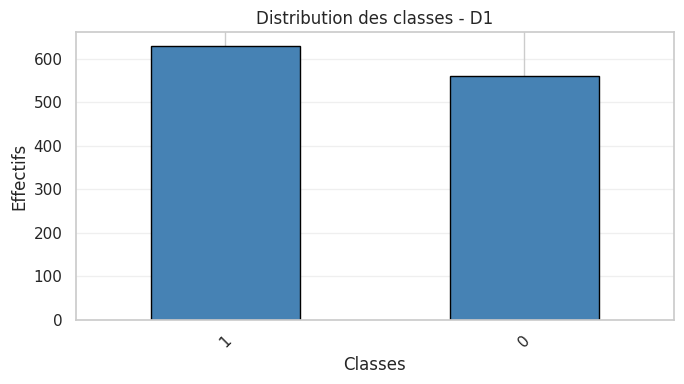

In [ ]:

name = "D1"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D1")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D2 – Analyse de la variable cible

Pour le dataset D2, la variable cible est transformée en classification binaire : les valeurs supérieures à zéro appartiennent à la classe 1, tandis que les valeurs égales à zéro appartiennent à la classe 0. Cette transformation permet d'étudier la distribution des deux classes et de mesurer leur éventuel déséquilibre.


,Effectif,Pourcentage (%)
num,,
0,164,54.13
1,139,45.87


Ratio majoritaire/minoritaire : 1.18
Classe minoritaire : 1
Pourcentage minoritaire : 45.87%
Déséquilibre : équilibré


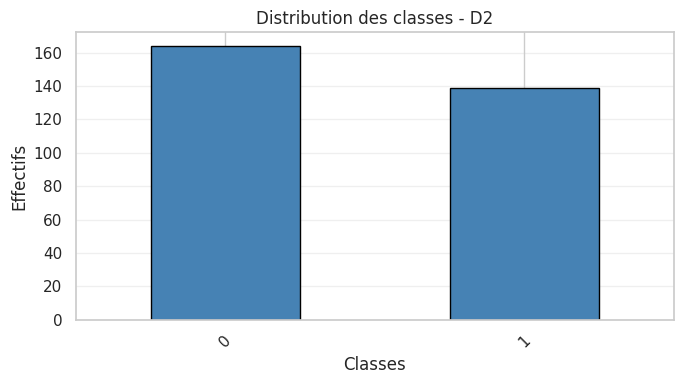

In [ ]:

name = "D2"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D2")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D3 – Analyse de la variable cible

L'analyse du dataset D3 porte sur la distribution de sa variable cible. Nous examinons le nombre d'observations dans chaque classe ainsi que leurs proportions respectives. Le ratio majoritaire/minoritaire permet de déterminer si les classes sont équilibrées ou présentent un déséquilibre.


,Effectif,Pourcentage (%)
target,,
1,526,51.32
0,499,48.68


Ratio majoritaire/minoritaire : 1.05
Classe minoritaire : 0
Pourcentage minoritaire : 48.68%
Déséquilibre : équilibré


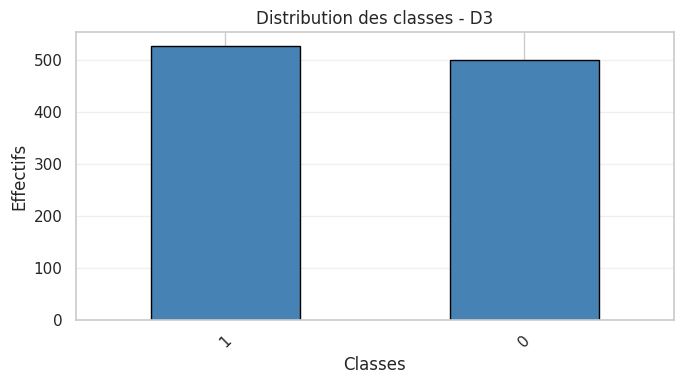

In [ ]:

name = "D3"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D3")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D4 – Analyse de la variable cible

Dans le dataset D4, la variable cible DEATH_EVENT représente l'événement étudié. L'analyse vise à comparer les observations appartenant aux différentes classes afin d'identifier un éventuel déséquilibre entre elles. Une attention particulière sera accordée à la proportion de la classe minoritaire.


,Effectif,Pourcentage (%)
DEATH_EVENT,,
0,203,67.89
1,96,32.11


Ratio majoritaire/minoritaire : 2.11
Classe minoritaire : 1
Pourcentage minoritaire : 32.11%
Déséquilibre : modéré


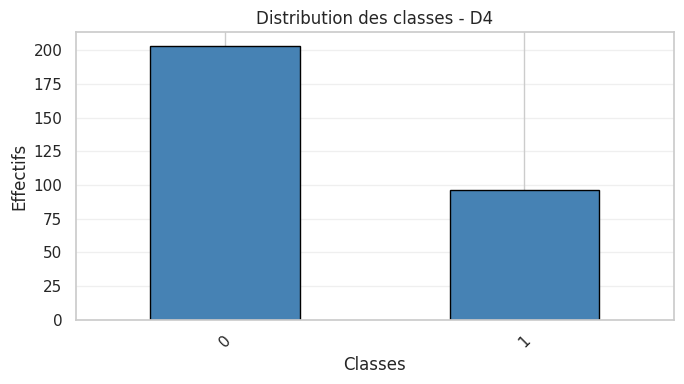

In [ ]:

name = "D4"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D4")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D5 – Analyse de la variable cible

Pour le dataset D5, nous étudions la distribution de la variable cible selector. Le calcul des effectifs et des pourcentages de chaque classe permet de comprendre la répartition des observations. Le ratio entre les classes majoritaire et minoritaire permet ensuite d'évaluer le niveau de déséquilibre.


In [ ]:

name = "D5"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D5")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D6 – Analyse de la variable cible

Le dataset D6 utilise la variable Selector comme variable cible. Nous analysons les effectifs et les proportions des différentes classes afin d'évaluer leur répartition. Le ratio majoritaire/minoritaire permet de déterminer le niveau de déséquilibre et d'anticiper les précautions nécessaires lors de la modélisation.


,Effectif,Pourcentage (%)
Selector,,
1,416,71.36
2,167,28.64


Ratio majoritaire/minoritaire : 2.49
Classe minoritaire : 2
Pourcentage minoritaire : 28.64%
Déséquilibre : modéré


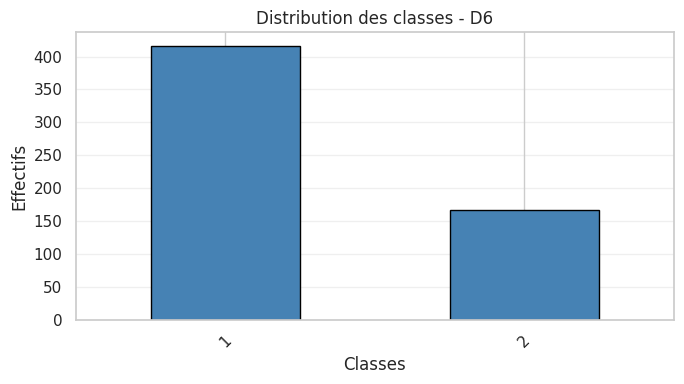

In [ ]:

name = "D6"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D6")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D7 – Analyse de la variable cible

Dans le dataset D7, la variable cible Cancer permet de distinguer les différentes classes étudiées. Nous examinons la fréquence de chaque classe et sa proportion dans le dataset. Cette analyse permet d'identifier une éventuelle prédominance d'une classe et d'évaluer l'importance du déséquilibre.


,Effectif,Pourcentage (%)
Cancer,,
Y,310,68.89
N,140,31.11


Ratio majoritaire/minoritaire : 2.21
Classe minoritaire : N
Pourcentage minoritaire : 31.11%
Déséquilibre : modéré


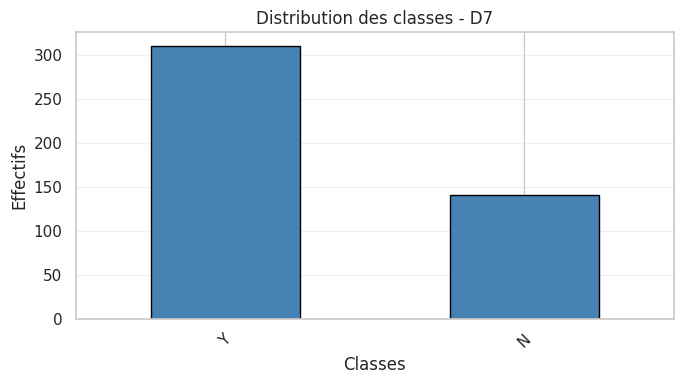

In [ ]:

name = "D7"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D7")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D8 – Analyse de la variable cible

L'analyse du dataset D8 porte sur la variable cible class. Nous étudions la distribution des observations entre les classes et calculons le ratio entre les effectifs majoritaire et minoritaire. Cette étape permet d'évaluer l'équilibre de la variable cible avant l'application des modèles de Machine Learning.


,Effectif,Pourcentage (%)
class,,
Positive,320,61.54
Negative,200,38.46


Ratio majoritaire/minoritaire : 1.60
Classe minoritaire : Negative
Pourcentage minoritaire : 38.46%
Déséquilibre : modéré


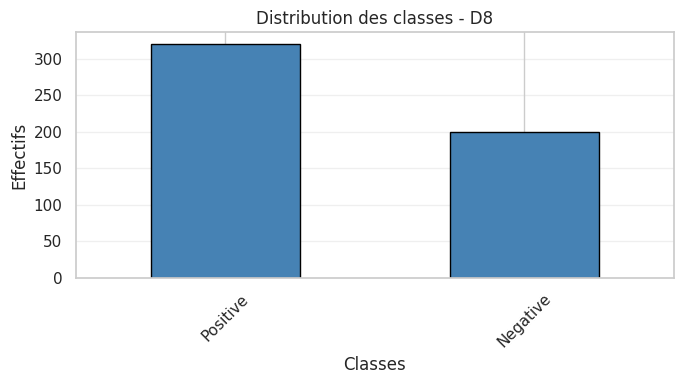

In [ ]:

name = "D8"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D8")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D9 – Analyse de la variable cible

Pour le dataset D9, la variable Outcome constitue la cible de classification. L'analyse compare les effectifs des différentes classes et leurs pourcentages respectifs. Nous utilisons le ratio majoritaire/minoritaire pour mesurer le déséquilibre et déterminer si des mesures particulières seront nécessaires pendant l'entraînement des modèles.


,Effectif,Pourcentage (%)
Outcome,,
0,500,65.1
1,268,34.9


Ratio majoritaire/minoritaire : 1.87
Classe minoritaire : 1
Pourcentage minoritaire : 34.90%
Déséquilibre : modéré


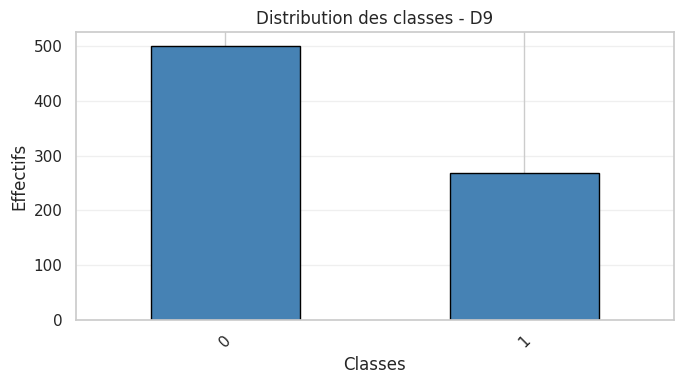

In [ ]:

name = "D9"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D9")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D10 – Analyse de la variable cible

Dans le dataset D10, la variable Diabetic est utilisée comme variable cible. Nous analysons la fréquence de chaque classe afin d'identifier la répartition des observations. Le calcul du pourcentage minoritaire et du ratio majoritaire/minoritaire permet de mesurer le degré de déséquilibre.


,Effectif,Pourcentage (%)
Diabetic,,
no,685,72.03
yes,266,27.97


Ratio majoritaire/minoritaire : 2.58
Classe minoritaire : yes
Pourcentage minoritaire : 27.97%
Déséquilibre : modéré


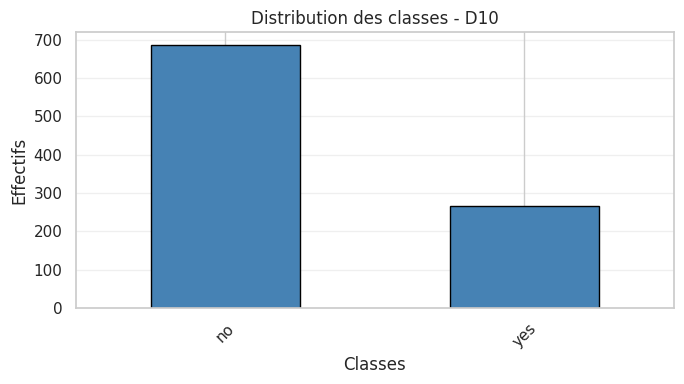

In [ ]:

name = "D10"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D10")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D11 – Analyse de la variable cible

Le dataset D11 possède Class comme variable cible. Nous étudions la distribution des différentes classes à travers leurs effectifs et leurs pourcentages. Le ratio entre la classe la plus représentée et la moins représentée permet de caractériser l'équilibre de la cible.


,Effectif,Pourcentage (%)
Class,,
1,611,53.08
0,540,46.92


Ratio majoritaire/minoritaire : 1.13
Classe minoritaire : 0
Pourcentage minoritaire : 46.92%
Déséquilibre : équilibré


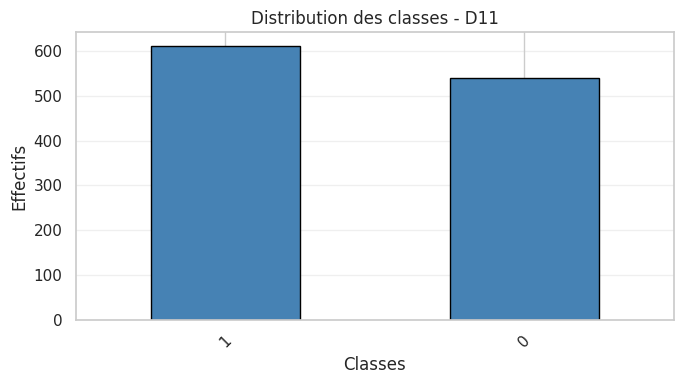

In [ ]:

name = "D11"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D11")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D12 – Analyse de la variable cible

Pour le dataset D12, la variable classification représente la variable à prédire. Nous étudions la distribution de ses classes et leurs proportions respectives. Cette analyse est particulièrement importante pour identifier les classes sous-représentées et évaluer les risques liés au déséquilibre des données.


In [ ]:

name = "D12"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D12")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D13 – Analyse de la variable cible

L'analyse du dataset D13 concerne la variable cible Class. Nous examinons les effectifs de chaque classe et leurs pourcentages afin de comprendre la répartition des observations. Le ratio majoritaire/minoritaire permet de déterminer si le dataset présente un déséquilibre important.


,Effectif,Pourcentage (%)
Class,,
1,250,62.5
0,150,37.5


Ratio majoritaire/minoritaire : 1.67
Classe minoritaire : 0
Pourcentage minoritaire : 37.50%
Déséquilibre : modéré


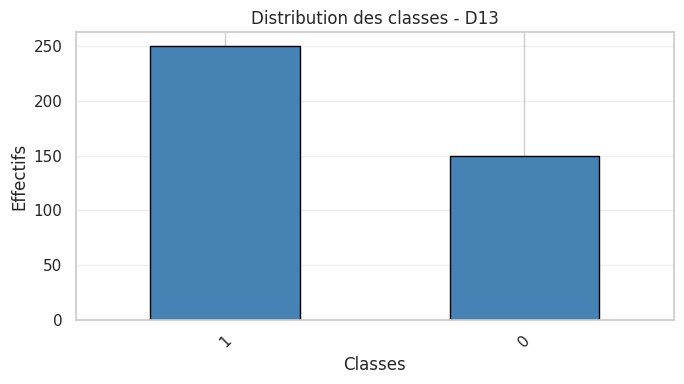

In [ ]:

name = "D13"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D13")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D14 – Analyse de la variable cible

Pour le dataset D14, la variable target constitue la cible de classification. Nous analysons les effectifs et les pourcentages des différentes classes. Le ratio majoritaire/minoritaire permet de mesurer le niveau de déséquilibre et de préparer une stratégie d'évaluation adaptée.


In [ ]:

name = "D14"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D14")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D15 – Analyse de la variable cible

Le dataset D15 utilise dx comme variable cible. Nous étudions la fréquence des différentes classes et leurs proportions respectives. L'objectif est d'identifier une éventuelle classe minoritaire et de mesurer le déséquilibre à l'aide du ratio majoritaire/minoritaire.


,Effectif,Pourcentage (%)
dx,,
nv,6705,66.95
mel,1113,11.11
bkl,1099,10.97
bcc,514,5.13
akiec,327,3.27
vasc,142,1.42
df,115,1.15


Ratio majoritaire/minoritaire : 58.30
Classe minoritaire : df
Pourcentage minoritaire : 1.15%
Déséquilibre : fort


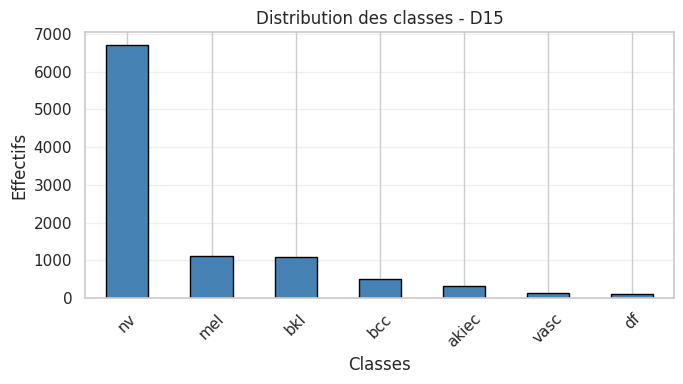

In [ ]:

name = "D15"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D15")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### D16 – Analyse de la variable cible

Enfin, le dataset D16 utilise class comme variable cible. Nous analysons la distribution des classes, leurs effectifs et leurs pourcentages. Le calcul du ratio majoritaire/minoritaire permet de déterminer le niveau de déséquilibre et de compléter la comparaison des seize datasets.


,Effectif,Pourcentage (%)
class,,
1,112,30.60
3,72,19.67
2,61,16.67
5,52,14.21
4,49,13.39
6,20,5.46


Ratio majoritaire/minoritaire : 5.60
Classe minoritaire : 6
Pourcentage minoritaire : 5.46%
Déséquilibre : fort


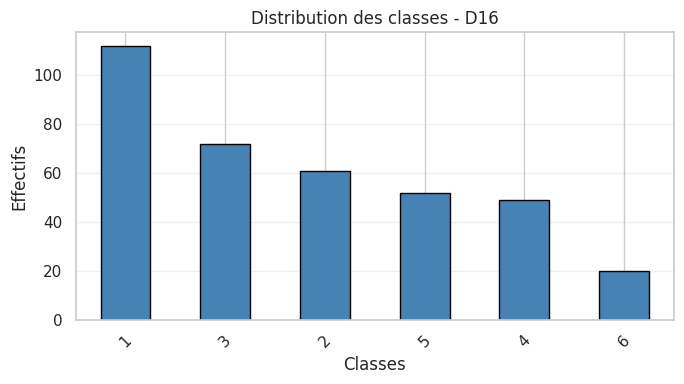

In [ ]:

name = "D16"
y = get_y(name)
vc = y.value_counts()

display(pd.DataFrame({
    "Effectif": vc,
    "Pourcentage (%)": (vc / vc.sum() * 100).round(2)
}))

if len(vc) >= 2:
    ratio = vc.max() / vc.min()
    print(f"Ratio majoritaire/minoritaire : {ratio:.2f}")
    print(f"Classe minoritaire : {vc.idxmin()}")
    print(f"Pourcentage minoritaire : {vc.min()/vc.sum()*100:.2f}%")
    print("Déséquilibre :", "fort" if ratio > 3 else "modéré" if ratio >= 1.5 else "équilibré")

vc.plot(kind="bar", figsize=(7,4), color="steelblue", edgecolor="black")
plt.title("Distribution des classes - D16")
plt.xlabel("Classes")
plt.ylabel("Effectifs")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### Conclusion – Analyse des variables cibles

L'analyse des variables cibles des seize datasets permet d'évaluer la distribution des classes et d'identifier les éventuels déséquilibres.

Le niveau de déséquilibre est déterminé à partir du ratio entre l'effectif de la classe majoritaire et celui de la classe minoritaire :

- Ratio inférieur à 1,5 : classes équilibrées.
- Ratio compris entre 1,5 et 3 : déséquilibre modéré.
- Ratio supérieur à 3 : déséquilibre fort.

Cette analyse est importante pour le choix des méthodes d'évaluation des modèles. En effet, l'accuracy seule peut être insuffisante en présence de classes déséquilibrées. Nous utiliserons également le recall, le F1-score et l'AUPRC afin d'obtenir une évaluation plus complète des performances.


## 2.9 Analyse des variables numériques

Exploration visuelle des distributions des variables numériques sur les datasets **D4, D6, D8, D12 et D16** (forme, asymétrie, dispersion).  

Les datasets restants sont synthétisés via les tableaux de statistiques descriptives.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
from IPython.display import display, clear_output
import ipywidgets as widgets

# -------------------------------------------------
# 1. List useful numeric columns for each dataset
# -------------------------------------------------
for name in ["D4", "D6", "D8", "D12", "D16"]:
    df = data[name]
    numeric_cols = df.select_dtypes(include="number").columns

    useful_cols = [
        col for col in numeric_cols
        if col != TARGETS[name]
        and df[col].nunique(dropna=True) > 1
        and df[col].notna().mean() >= 0.5
    ]

    print(f"\n{name} - Colonnes numériques utiles :")
    print(useful_cols)

# -------------------------------------------------
# 2. Function to plot nice histograms
# -------------------------------------------------
def plot_histograms(dataset_name, columns):
    """Plot attractive histograms for the given columns of a dataset."""
    df = data[dataset_name]

    n = len(columns)
    if n == 0:
        print(f"→ Aucune colonne à afficher pour {dataset_name}")
        return

    cols = min(3, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5.5 * cols, 4.2 * rows))

    if n == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    colors = plt.cm.Set2(np.linspace(0, 1, max(n, 1)))

    for i, col in enumerate(columns):
        ax = axes[i]
        series = df[col].dropna()

        ax.hist(series, bins=25, color=colors[i], edgecolor="black", alpha=0.85)
        ax.set_title(col, fontsize=12, fontweight="bold", pad=8)
        ax.set_xlabel(col)
        ax.set_ylabel("Fréquence")
        ax.grid(axis="y", alpha=0.3, linestyle="--")

        # Mean line
        mean_val = series.mean()
        ax.axvline(mean_val, color="crimson", linestyle="--", linewidth=1.8,
                   label=f"Moyenne = {mean_val:.2f}")
        ax.legend(fontsize=9)

    # Hide empty subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(f"Distributions – {dataset_name}", fontsize=15, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

# -------------------------------------------------
# 3. Interactive widgets
# -------------------------------------------------
dataset_dropdown = widgets.Dropdown(
    options=["All", "D4", "D6", "D8", "D12", "D16"],
    value="All",
    description="Dataset :",
    style={'description_width': '80px'}
)

column_text = widgets.Text(
    value="",
    placeholder="Laisse vide → 3 aléatoires | Tape un nom de colonne",
    description="Colonne :",
    layout=widgets.Layout(width="480px"),
    style={'description_width': '80px'}
)

button = widgets.Button(
    description=" Afficher",
    button_style="primary",
    layout=widgets.Layout(width="150px")
)

output = widgets.Output()

def on_button_clicked(b):
    with output:
        clear_output(wait=True)

        selected_datasets = ["D4", "D6", "D8", "D12", "D16"] if dataset_dropdown.value == "All" else [dataset_dropdown.value]
        requested = column_text.value.strip()

        for name in selected_datasets:
            df = data[name]

            # Useful columns for this dataset
            numeric_cols = df.select_dtypes(include="number").columns
            useful_cols = [
                col for col in numeric_cols
                if col != TARGETS[name]
                and df[col].nunique(dropna=True) > 1
                and df[col].notna().mean() >= 0.5
            ]

            print(f"\n{'='*60}")
            print(f" Dataset : {name}")
            print(f"{'='*60}")

            if requested == "":
                # Default → 3 random histograms
                if not useful_cols:
                    print("Aucune colonne utile.")
                    continue
                selected = random.sample(useful_cols, min(3, len(useful_cols)))
                print(f"3 histogrammes aléatoires : {selected}")
                plot_histograms(name, selected)
            else:
                # Specific column requested
                if requested not in useful_cols:
                    print(f"La colonne '{requested}' n'existe pas (ou n'est pas utile) dans {name}.")
                    print(f"Colonnes disponibles : {useful_cols}")
                    continue
                print(f"Histogramme de '{requested}'")
                plot_histograms(name, [requested])

button.on_click(on_button_clicked)

# Display the interface
print("Interface interactive prête :")
display(dataset_dropdown, column_text, button, output)


D4 - Colonnes numériques utiles :
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time']

D6 - Colonnes numériques utiles :
['Age', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'AG']

D8 - Colonnes numériques utiles :
['Age']

D12 - Colonnes numériques utiles :
['id', 'age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo']

D16 - Colonnes numériques utiles :
['f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21', 'f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31', 'f32', 'f33', 'f34']
Interface interactive prête :


Dropdown(description='Dataset :', options=('All', 'D4', 'D6', 'D8', 'D12', 'D16'), style=DescriptionStyle(desc…

Text(value='', description='Colonne :', layout=Layout(width='480px'), placeholder='Laisse vide → 3 aléatoires …

Button(button_style='primary', description=' Afficher', layout=Layout(width='150px'), style=ButtonStyle())

Output()

## 2.10 Analyse des valeurs aberrantes

Les outliers sont détectés avec la règle de l'IQR (valeurs au-delà de 1,5 × IQR). En santé, une valeur extrême n'est pas forcément une erreur : elle peut correspondre à un patient atypique. Elles sont donc analysées avant toute suppression.

In [ ]:
rows = []
for name in ORDER:
    X = data[name].drop(columns=[TARGETS[name]], errors="ignore").select_dtypes("number")
    q1, q3 = X.quantile(.25), X.quantile(.75); iqr = q3 - q1
    out = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).mean() * 100
    rows.append({"Dataset": name, "Variables numériques": X.shape[1],
                 "Pire % outliers": round(out.max(), 1) if len(out) else 0,
                 "Variable": out.idxmax() if len(out) else "-"})
outlier_table = pd.DataFrame(rows)
display(outlier_table)

,Dataset,Variables numériques,Pire % outliers,Variable
0,D1,11,23.6,sex
1,D2,13,14.9,fbs
2,D3,13,14.9,fbs
3,D4,12,9.7,creatinine_phosphokinase
4,D5,6,8.1,sgpt
5,D6,9,14.4,TB
6,D7,9,4.2,Size
7,D8,1,0.8,Age
8,D9,8,5.9,BloodPressure
9,D10,4,16.4,Pregancies


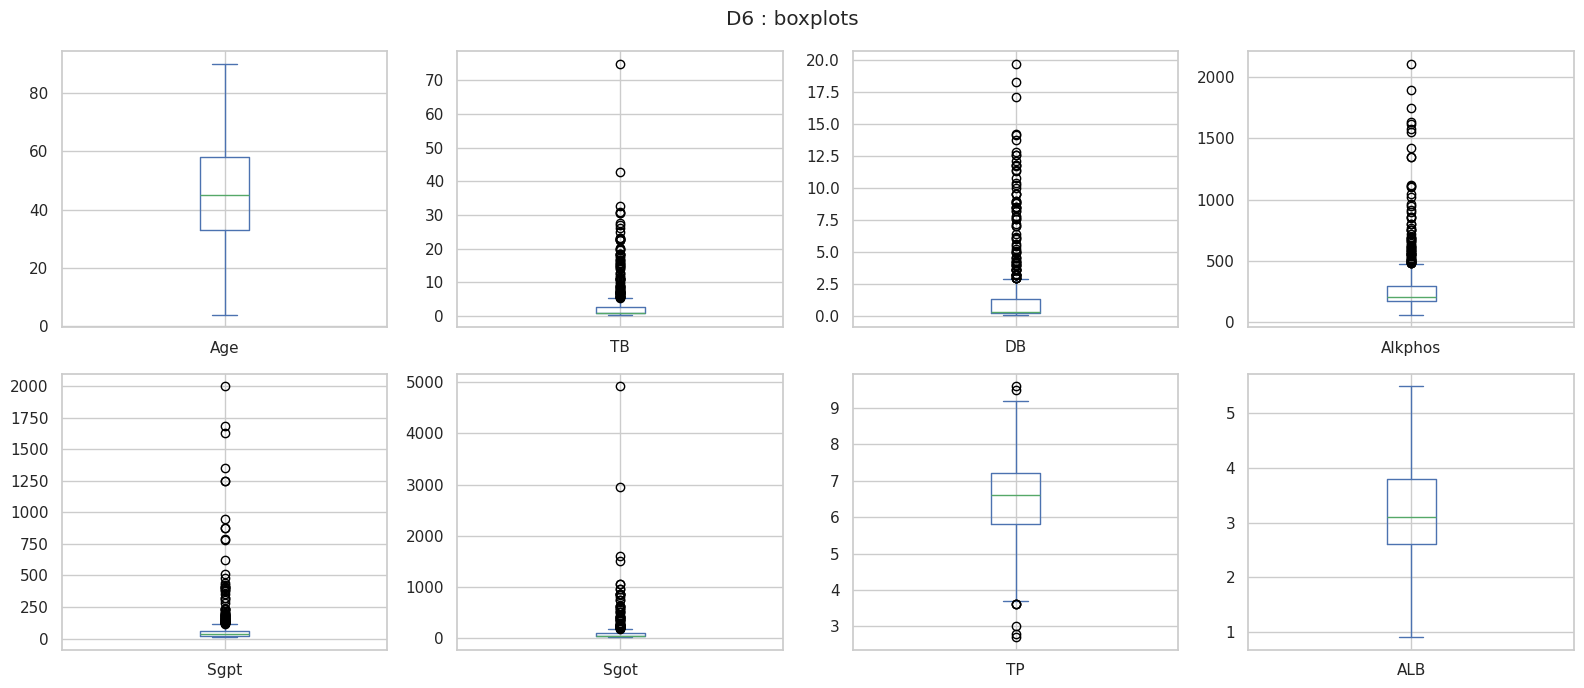

In [ ]:

name = "D6"
X = data[name].select_dtypes("number").iloc[:, :8]
X.plot(kind="box", subplots=True, layout=(2, 4), figsize=(16, 7), sharex=False, sharey=False)
plt.suptitle(f"{name} : boxplots"); plt.tight_layout(); plt.show()

## 2.11 Matrice de corrélation

La corrélation permet d'identifier les variables qui évoluent ensemble et celles très liées à la cible. Une corrélation ne signifie pas une causalité. Une corrélation presque parfaite avec la cible peut aussi révéler une fuite de données.

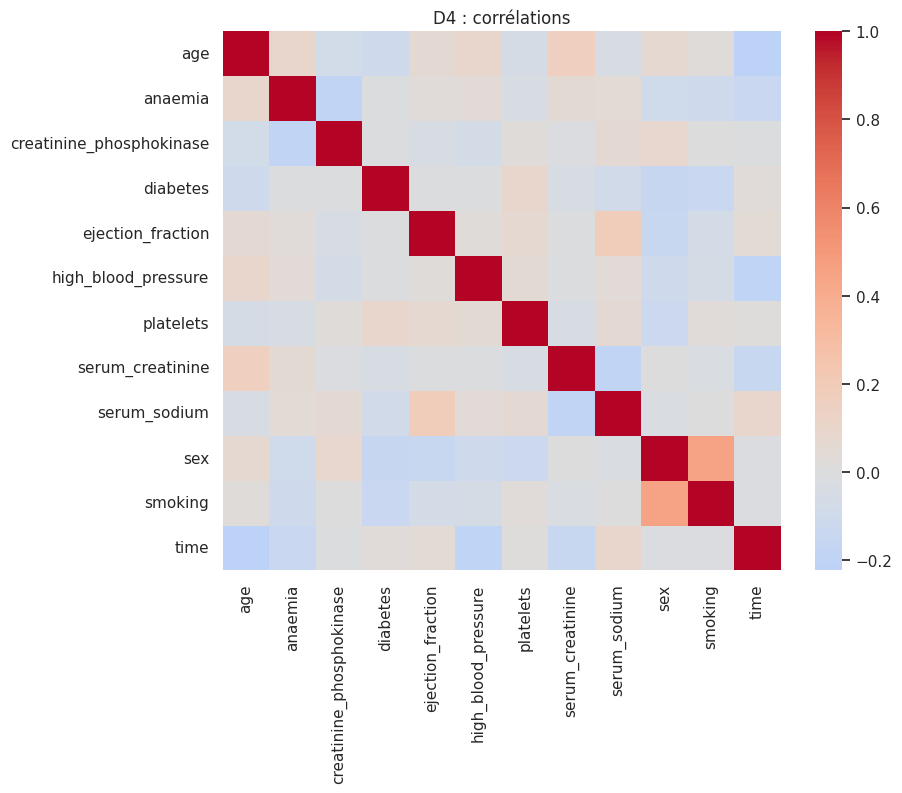

In [ ]:

plot_corr("D4", max_cols=12)



### 2.11.2 Matrice de corrélation – Dataset D6

Cette matrice permet d'étudier les corrélations entre les variables numériques du dataset D6 et d'identifier les relations importantes entre elles.


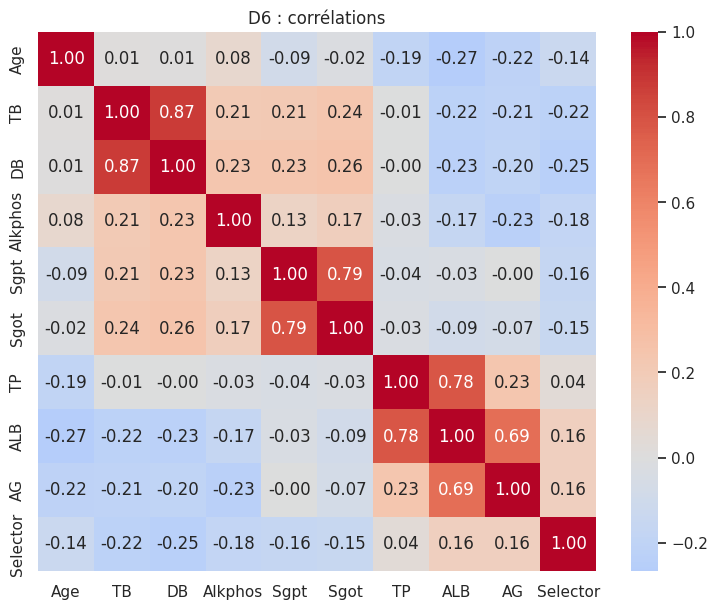

In [ ]:

plot_corr("D6", max_cols=12)



### 2.11.3 Matrice de corrélation – Dataset D8

Cette matrice permet de visualiser les relations entre les variables numériques du dataset D8 afin de détecter les variables fortement corrélées.


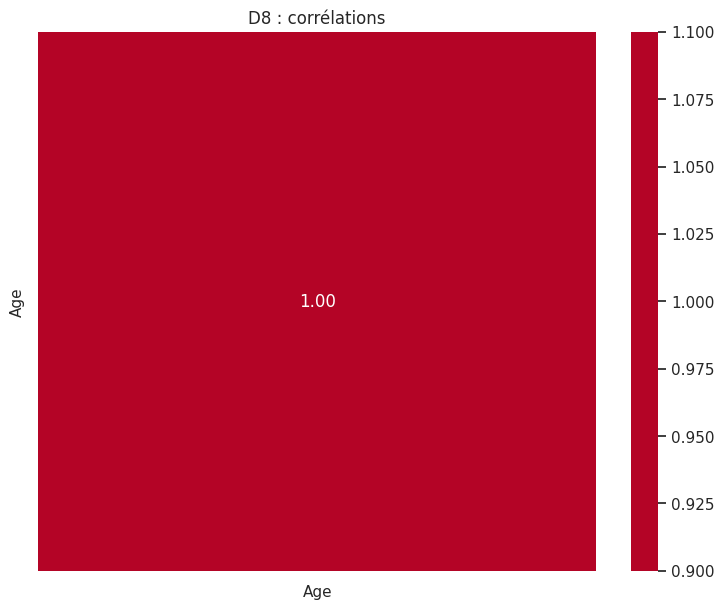

In [ ]:

plot_corr("D8", max_cols=12)



### 2.11.4 Matrice de corrélation – Dataset D12

Cette matrice permet d'analyser les relations entre les variables numériques du dataset D12 et de repérer les éventuelles corrélations fortes.


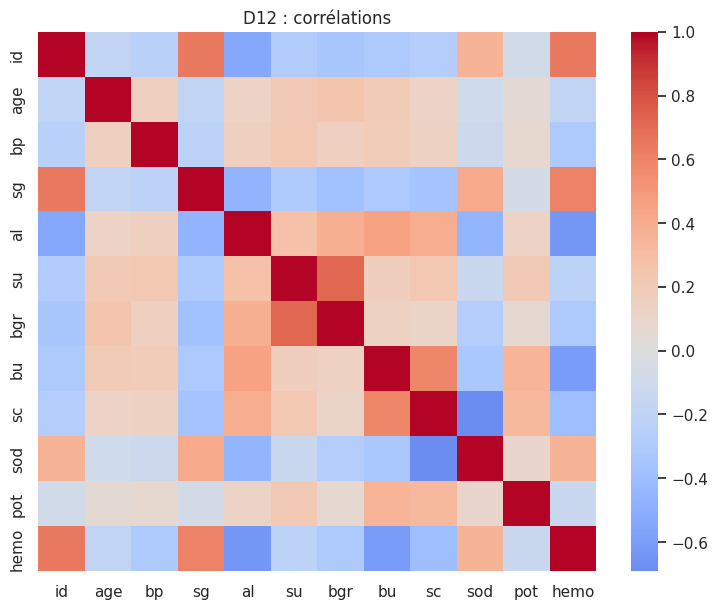

In [ ]:

plot_corr("D12", max_cols=12)



### 2.11.5 Matrice de corrélation – Dataset D16

Cette matrice permet d'examiner les relations entre les variables numériques du dataset D16 et d'identifier les variables qui présentent des corrélations importantes.


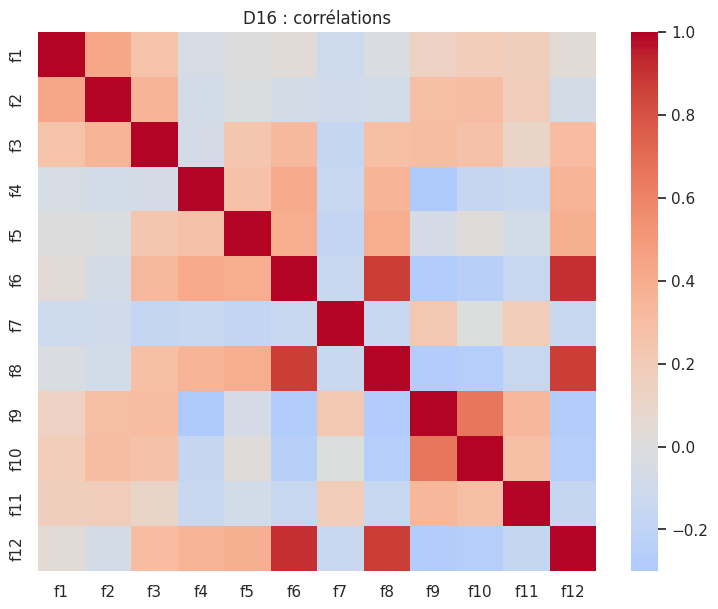

In [ ]:

plot_corr("D16", max_cols=12)


In [ ]:
# Variables les plus liées à la cible (alerte fuite si |corr| > 0,9)
rows = []
for name in ORDER:
    df = data[name]; y = get_y(name)
    X = df.loc[y.index].drop(columns=[TARGETS[name]], errors="ignore").select_dtypes("number")
    yn = pd.factorize(y)[0]
    c = X.apply(lambda s: s.fillna(s.median()).corr(pd.Series(yn, index=X.index))).abs()
    rows.append({"Dataset": name, "Variable la plus liée à la cible": c.idxmax() if len(c) else "-",
                 "|corr|": round(c.max(), 2) if len(c) else None})
display(pd.DataFrame(rows))

,Dataset,Variable la plus liée à la cible,|corr|
0,D1,ST slope,0.51
1,D2,thal,0.52
2,D3,oldpeak,0.44
3,D4,time,0.53
4,D5,sgot,0.16
5,D6,DB,0.25
6,D7,Survival_fromMDM,0.15
7,D8,Age,0.11
8,D9,Glucose,0.47
9,D10,Pregancies,0.24


## 2.12 Identification des problèmes de Data Quality

Après l'exploration initiale, nous résumons pour chaque dataset les doublons, les colonnes constantes, les valeurs manquantes et le déséquilibre.

In [ ]:

import pandas as pd

# -------------------------------------------------
# Quality analysis for all datasets
# -------------------------------------------------

rows = []

for name in ORDER:

    df = data[name]

    # Exclude target variable
    X = df.drop(columns=[TARGETS[name]], errors="ignore")

    # Calculate quality indicators
    rows.append({
        "Dataset": name,

        "Doublons": int(df.duplicated().sum()),

        "% doublons": round(
            100 * df.duplicated().mean(), 1
        ),

        "Colonnes constantes": int(
            (X.nunique(dropna=True) <= 1).sum()
        ),

        "Cellules manquantes": int(
            df.isna().sum().sum()
        )
    })


# -------------------------------------------------
# Create quality summary table
# -------------------------------------------------

quality = pd.DataFrame(rows)

# Add target imbalance information
quality = quality.merge(
    target_table[
        ["Dataset", "Ratio maj/min", "Déséquilibre"]
    ],
    on="Dataset",
    how="left"
)

# Display results
print("RÉSUMÉ DE LA QUALITÉ DES DATASETS")
display(quality)


# -------------------------------------------------
# Export results
# -------------------------------------------------

quality.to_csv(
    "quality_summary.csv",
    index=False
)

print("Fichier quality_summary.csv enregistré avec succès !")


RÉSUMÉ DE LA QUALITÉ DES DATASETS


,Dataset,Doublons,% doublons,Colonnes constantes,Cellules manquantes,Ratio maj/min,Déséquilibre
0,D1,272,22.9,0,0,1.12,équilibré
1,D2,0,0.0,0,6,1.18,équilibré
2,D3,723,70.5,0,0,1.05,équilibré
3,D4,0,0.0,0,0,2.11,modéré
4,D5,4,1.2,0,0,1.38,équilibré
5,D6,13,2.2,0,4,2.49,modéré
6,D7,0,0.0,0,3894,2.21,modéré
7,D8,269,51.7,0,0,1.60,modéré
8,D9,0,0.0,0,0,1.87,modéré
9,D10,622,65.3,0,48,2.58,modéré


Fichier quality_summary.csv enregistré avec succès !


### Problèmes identifiés

1. **Valeurs manquantes :** (datasets, colonnes, %)
2. **Doublons :** (datasets avec beaucoup de doublons ; risque de fuite entre train et test)
3. **Cibles à nettoyer :** (dataset, valeurs incohérentes)
4. **Déséquilibre des classes :** (datasets avec ratio ≥ 2 ; classe minoritaire)
5. **Datasets multiclasses :** D15, D16 (moyenne macro)
6. **Écarts avec le Table 2 :** (dataset, écart de lignes ou de colonnes, explication)
7. **Risques de fuite de données :** (dataset, variable, raison)
8. **Limites connues :** D5 (la cible `selector` sépare train et test selon UCI, et ne représente pas une maladie), D14 (90 lignes)

Ces problèmes seront traités dans l'étape suivante : Data Preparation.